#Predicting Hospitalisation Periods of Colon Patients
- Using Decision Trees and Ensemble Classifiers

### Notebook Workflow
- Part 1: Importing and formatting the data set
- Part 2: Fitting a single decision tree
- Part 3: Using a Random Forest Classifier
- Part 4: Using the AdaBoost classifier
- Part 5: Using the Bagging classifier
- Part 6: Using XGBoost
- Part 7: Using LightGBM
- Part 8: Comparing Classifiers
- Part 9: Choosing the best classifier, retraining using all the samples and testing on the test set (model selection)
- Part 10: Feature selection

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn import tree, ensemble
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import permutation_importance
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

###**Part 1**: Importing and formatting the data set

The dataset used in this notebook is from the University of Medicine and Pharmacy of Craiova, Romania.
- The aim of the dataset is to predict the hospitalisation period of patients after colon cancer operations based on socio-economic variables and clinical information.
- More information about the data and its origins [here](https://figshare.com/articles/dataset/LOS_Colon_Cancer_621_cases/4747246/1).

In [ ]:
df = pd.read_csv('/content/colon_data.csv')
len(df)

298

In [ ]:
print(df.columns)

Index(['AGE', 'SEX', 'TOPOGRAPHY', 'STAGE', 'T', 'N', 'M', 'SURGERY', 'CLASS'], dtype='object')


In [ ]:
df.head()

,AGE,SEX,TOPOGRAPHY,STAGE,T,N,M,SURGERY,CLASS
0,64,M,rect,three,T4,Nx,Mx,ten,medium
1,70,M,rect,three,T4,Nx,Mx,ten,medium
2,76,F,cec,three,T3,Nx,Mx,three,medium
3,62,M,cec,three,T2,Nx,Mx,three,short
4,62,M,cec,two,T2,Nx,Mx,three,short


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298 entries, 0 to 297
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   AGE         298 non-null    int64 
 1   SEX         298 non-null    object
 2   TOPOGRAPHY  298 non-null    object
 3   STAGE       298 non-null    object
 4   T           298 non-null    object
 5   N           298 non-null    object
 6   M           298 non-null    object
 7   SURGERY     298 non-null    object
 8   CLASS       298 non-null    object
dtypes: int64(1), object(8)
memory usage: 21.1+ KB


Check the unique() values of df['CLASS'], then replace the categorical values of the CLASS variable with numerical values.

In [ ]:
df['CLASS'].unique()

array(['medium', 'short', 'long'], dtype=object)

####1 Encode categorical variables

The target class `CLASS` has three unique values. These values are mapped to numerical values for use in tree ensemble methods.
- Using `map()` to convert `short`,`medium` and `long` to 1,2 and 3, respectively.

In [ ]:
df_copy = df.copy()
class_map = {
    'short' : 1,
    'medium' : 2,
    'long' : 3
}
df_copy['CLASS'] = df_copy['CLASS'].map(class_map)

print(df_copy['CLASS'])

0      2
1      2
2      2
3      1
4      1
      ..
293    1
294    1
295    2
296    3
297    3
Name: CLASS, Length: 298, dtype: int64


####2 Encoding categorical values
- Use `LabelEncoder()` to convert the categorical columns into encoded numerical columns.

- Concatenate these with the target variable `CLASS` to create the combined data set.

In [ ]:
#List categorical columns
df_copy2 = df.copy()
df_copy2 = df_copy2.drop(columns='CLASS')
cat_cols = df_copy2.select_dtypes(include=['object']).columns.tolist()
print(cat_cols)

['SEX', 'TOPOGRAPHY', 'STAGE', 'T', 'N', 'M', 'SURGERY']


In [ ]:
label_enc = LabelEncoder()

# Apply label encoding to each
for col in cat_cols:
    df[col] = label_enc.fit_transform(df[col])

In [ ]:
combined_df = pd.concat([df[cat_cols], df_copy['CLASS']], axis=1) #exclude age as a predictor

In [ ]:
combined_df.rename(columns={'CLASS': 'CLASS_mapped'}, inplace=True)
print(combined_df.head())

   SEX  TOPOGRAPHY  STAGE  T  N  M  SURGERY  CLASS_mapped
0    1           6      2  3  3  3        0             2
1    1           6      2  3  3  3        0             2
2    0           0      2  2  3  3        1             2
3    1           0      2  1  3  3        1             1
4    1           0      3  1  3  3        1             1


Convert the df into a `NumPy` array for simplicity


In [ ]:
Xy=np.array(combined_df)

Split X (the features) and y (the outcome, 'CLASS')

In [ ]:
X=Xy[:,:-1]
y=Xy[:,-1]

Split $X$ and $y$ into training, validation and test sets.

In [ ]:
trainsize = int(len(df)/2)
trainplusvalsize = int(len(df)/4)
X_train=X[:trainsize]
X_val=X[trainsize:trainsize + trainplusvalsize]
X_test=X[trainsize + trainplusvalsize:]

y_train=y[:trainsize]
y_train = pd.Categorical(y_train)
y_val=y[trainsize:trainsize + trainplusvalsize]
y_test=y[trainsize + trainplusvalsize:]

### **Part 2:** Fit a decision tree


**Format for the code below:**

    # For i in range(max_depth):
    #  compute new classifier clf with depth = max_depth = i+1
    #  fit the X and y training sets with the new classifier
    #  compute the updated trainscore using .score() on the training set
    #  compute the updated valscore using .score() on the validation set
    #  print the scores
    print ( 'Depth:', i+1, 'Training Score:', trainscore, 'Validation Score:', valscore)
     
    # If valscore is better than bestscore and trainscore is greater than or equal to min_train_score:
        # update the value of bestscore
        # increase bestdepth by one unit

In [ ]:
max_depth = 15
bestdepth = -1
bestscore = 0
min_train_score = 0.7

for i in range(max_depth):
    clf = tree.DecisionTreeClassifier(max_depth=i+1)
    clf.fit(X_train, y_train)
    trainscore = clf.score(X_train, y_train)
    valscore = clf.score(X_val, y_val)
    print('Depth:', i+1, 'Train Score:', trainscore, 'Validation Score:', valscore)

    if valscore > bestscore and trainscore >= min_train_score:
        bestscore = valscore
        bestdepth = i+1

print(f'This is the best depth: {bestdepth}, and this is the best score {bestscore}')

Depth: 1 Train Score: 0.5771812080536913 Validation Score: 0.6891891891891891
Depth: 2 Train Score: 0.697986577181208 Validation Score: 0.2702702702702703
Depth: 3 Train Score: 0.785234899328859 Validation Score: 0.6891891891891891
Depth: 4 Train Score: 0.7986577181208053 Validation Score: 0.7297297297297297
Depth: 5 Train Score: 0.8456375838926175 Validation Score: 0.7297297297297297
Depth: 6 Train Score: 0.8791946308724832 Validation Score: 0.7162162162162162
Depth: 7 Train Score: 0.9060402684563759 Validation Score: 0.7297297297297297
Depth: 8 Train Score: 0.9060402684563759 Validation Score: 0.6621621621621622
Depth: 9 Train Score: 0.9261744966442953 Validation Score: 0.7162162162162162
Depth: 10 Train Score: 0.9328859060402684 Validation Score: 0.6891891891891891
Depth: 11 Train Score: 0.9328859060402684 Validation Score: 0.6756756756756757
Depth: 12 Train Score: 0.9328859060402684 Validation Score: 0.7162162162162162
Depth: 13 Train Score: 0.9328859060402684 Validation Score: 0.7

In [ ]:
#Save predictions for clf
clf = tree.DecisionTreeClassifier(max_depth=4) #max_depth from best model
clf.fit(X_train, y_train)
ypred1 = clf.predict(X_val)

### **Part 3:** Using a Random Forest classifier

In [ ]:
#Initiliase the random forest classifier
from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier()
rf_clf.fit(X_train, y_train)
ypred2 = rf_clf.predict(X_val)

In [ ]:
print ( 'Full tree guess train/validation ',rf_clf.score(X_train, y_train),rf_clf.score(X_val, y_val))

Full tree guess train/validation  0.9328859060402684 0.7432432432432432


Random Forest Classifiers are able to consider all or a subset of features at each split. This is controlled by `max_features`.
- Considering fewer features can make the model more random, which reduces overfitting. However, too few features can lead to underfitting.
- Default: set to `'sqrt'` in scikit-learn, which selects the square root of the total number of features (this is typically the "rule of thumb")

The following code explores setting `max_features` to `'sqrt'` vs setting it to `None`. When `max_features = None`, the algorithm uses all features at every split.



In [ ]:
# For loop looking at RF with different max_features:

np.random.seed(1)
for max_features in ["sqrt",  None]:
    # build the rf classifier wwith different arguments for max_features
    # fit it to the training data
    rf_clf = ensemble.RandomForestClassifier(max_features = max_features)
    rf_clf.fit(X_train, y_train)

    print ( f'Full tree guess train/validation {max_features}',rf_clf.score(X_train, y_train),rf_clf.score(X_val, y_val))

Full tree guess train/validation sqrt 0.9328859060402684 0.7027027027027027
Full tree guess train/validation None 0.9328859060402684 0.7027027027027027


###**Part 4:** Using AdaBoost classifier (boosting)

AdaBoost is an adaptive boosting algorithm; it adjusts sample weights and weak learner coefficients α at each tree.

AdaBoost follows the following equation:

$\alpha = \frac{1}{2} \ln \left( \frac{1 - \epsilon}{\epsilon} \right)$\
Where ϵ is the learner's error rate.

In [ ]:
ab_clf = ensemble.AdaBoostClassifier()
ab_clf.fit(X_train, y_train)
ypred3 = ab_clf.predict(X_val)

In [ ]:
print ( 'Full tree guess train/validation ',ab_clf.score(X_train, y_train),ab_clf.score(X_val, y_val))

Full tree guess train/validation  0.738255033557047 0.6891891891891891


###**Part 5:** Using the bagging classifier

The `sklearn.ensemble.BaggingClassifier` is and ensemble meta-estimator fits base classifiers on random subsets of the original data and combines their predictions to produce the final output.

- `DecisionTreeClassifier()` used as the base classifier
- `BaggingClassifier` used with the following parameters:
  - estimator = `base_clf`
  - n_estimators = 50
  - random_state = 42

In [ ]:
#Initialised the bagging classifier
base_clf = DecisionTreeClassifier()
bagging_clf = BaggingClassifier(estimator = base_clf, n_estimators = 50, random_state = 42)
bagging_clf.fit(X_train, y_train)
ypred4 = bagging_clf.predict(X_val)

In [ ]:
print ( 'Full tree guess train/validation ',bagging_clf.score(X_train, y_train),bagging_clf.score(X_val, y_val))

Full tree guess train/validation  0.9328859060402684 0.7297297297297297


###**Part 6:** Using XGBoost
XGBoost (eXtreme Gradient Boosting) is a boosting method that integrates regularisation terms (L1/L2 penalities) into the loss function.

The integration of regularisation terms prevents overfitting, making XGBoost more robust and generalisable than classic Gradient Boosting.

In [ ]:
from xgboost import XGBClassifier
from timeit import default_timer as timer

# Need to map [1, 2, 3] target classes to [0, 1, 2] as XGBoost requires class labels to be integers starting from 0
le = LabelEncoder()
y_train_idxed = le.fit_transform(y_train)
y_val_idxed = le.transform(y_val)

xgb_clf = XGBClassifier()
start = timer() #use timer to see training time
xgb_clf.fit(X_train, y_train_idxed)
train_time = timer() - start
ypred5 = xgb_clf.predict(X_val)

print('Full tree guess train/validation ', xgb_clf.score(X_train, y_train_idxed), xgb_clf.score(X_val, y_val_idxed))
print('The training time was {:.4f} seconds'.format(train_time))

Full tree guess train/validation  0.9261744966442953 0.6891891891891891
The training time was 0.0629 seconds


###**Part 7:** Using LightGBM
LightGBM was developed for efficiency, scalability and high accuracy with large datasets.

It implements techniques such as Gradient-based One-side Sampling (GOSS) and Exclusive Feature Bundling (EFB) to enhance memory effiency.

As this is a small dataset, we are just showing how it works here.

In [ ]:
from lightgbm import LGBMClassifier
lgb_clf = LGBMClassifier

lgb_clf = XGBClassifier()
start = timer()
lgb_clf.fit(X_train, y_train_idxed)
train_time = timer() - start
ypred6 = lgb_clf.predict(X_val)

print('Full tree guess train/validation ', lgb_clf.score(X_train, y_train_idxed), lgb_clf.score(X_val, y_val_idxed))
print('The training time was {:.4f} seconds'.format(train_time))

Full tree guess train/validation  0.9261744966442953 0.6891891891891891
The training time was 0.0615 seconds


You can see that the training time is slightly faster than with XGBoost.

###**Part 8:** Comparing the results of each classifier

Text(0, 0.5, 'y_pred')

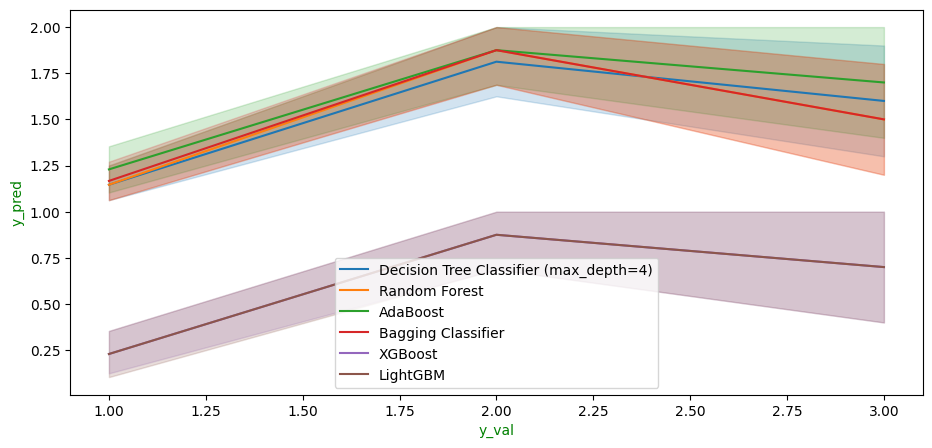

In [ ]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(11, 5))

ax = sns.lineplot(x=y_val, y=ypred1,
                  label='Decision Tree Classifier (max_depth=4)')
ax1 = sns.lineplot(x=y_val, y=ypred2,
                   label='Random Forest')
ax2 = sns.lineplot(x=y_val, y=ypred3,
                   label='AdaBoost')
ax3 = sns.lineplot(x=y_val, y=ypred4,
                   label='Bagging Classifier')
ax4 = sns.lineplot(x=y_val, y=ypred5,
                   label='XGBoost')
ax5 = sns.lineplot(x=y_val, y=ypred6,
                   label='LightGBM')

ax.set_xlabel('y_val', color='g')
ax.set_ylabel('y_pred', color='g')

### **Part 9:** Choosing the best classifier, retraining using all the samples and testing on the test set (model selection)

Retrain the best model with both the training and validation data and test it on the test data.

In [ ]:
X_trainval = X[:trainsize + trainplusvalsize, :]
y_trainval = y[:trainsize + trainplusvalsize]
y_trainval = y_trainval.astype(int)

best_clf = ensemble.RandomForestClassifier()
best_clf.fit(X_trainval, y_trainval)

# Convert y_test to integer type to match y_trainval
y_test = y_test.astype(int)
print ( 'Full tree guess train/validation ',best_clf.score(X_trainval, y_trainval),best_clf.score(X_test, y_test))

Full tree guess train/validation  0.9192825112107623 0.8266666666666667



### **Part 10:** Feature selection

Feature selection helps makes sense of your model’s behaviour and remove predictors that don’t add value. The most important features in a decision tree can be determined using two methods:

- Impurity-based metrics

- Permutation importances

In [ ]:
feature_importances = best_clf.feature_importances_
sorted_idx = feature_importances.argsort()

print(feature_importances)
print(sorted_idx)

[0.05966947 0.31414666 0.09897193 0.27846099 0.11711726 0.05468988
 0.07694381]
[5 0 6 2 4 3 1]


In [ ]:
feature_names = combined_df.columns[:-1]

Plot the importances.

In [ ]:
def plot_impurity_metric_features(feature_importances, sorted_idx, feature_names):
    y_ticks = np.arange(0, len(feature_names)) #creates object that has the feature names to plot x values against
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.barh(y_ticks, feature_importances[sorted_idx])
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(feature_names[sorted_idx])
    ax.set_title("Random Forest Feature Importances")
    fig.tight_layout()
    plt.show()

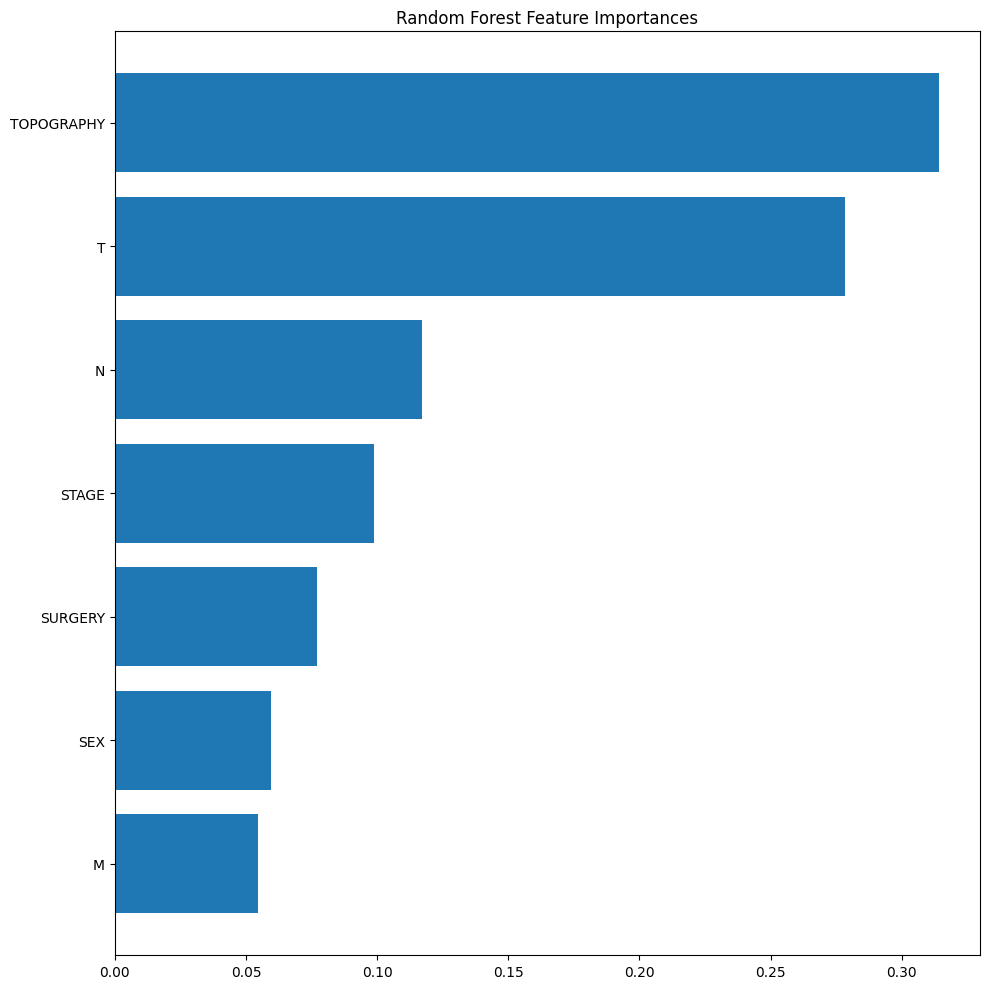

In [ ]:
# Plot the impurity metric feature importances
plot_impurity_metric_features(feature_importances, sorted_idx, feature_names)

One limitation of the built-in impurity metric is that it only applies to the training data. It doesn't tell you which features are likely to be important on unseen data.

Permutation importance can be used to measure feature importance on both the training and validation sets.

####Using Permutation Importance

Using the `permutation_importance` function with the following hyperparameters:
- `n_repeats` is assigned a value 10.
- `n-jobs` is assigned a value 2.

In [ ]:
### GRADED
result = None
sorted_idx = None

# YOUR CODE HERE
result = permutation_importance(estimator=best_clf, X = X_train, y = y_train, n_repeats = 10, n_jobs = 2)
sorted_idx = result.importances_mean.argsort()

### Answer test
print(result)
print(sorted_idx)

{'importances_mean': array([0.05033557, 0.27583893, 0.09731544, 0.36375839, 0.14161074,
       0.04362416, 0.09798658]), 'importances_std': array([0.01447239, 0.0314005 , 0.0091285 , 0.02697953, 0.02110629,
       0.00618761, 0.0185507 ]), 'importances': array([[0.05369128, 0.02684564, 0.06040268, 0.05369128, 0.04697987,
        0.06040268, 0.06711409, 0.05369128, 0.02013423, 0.06040268],
       [0.29530201, 0.32214765, 0.26845638, 0.32214765, 0.27516779,
        0.27516779, 0.28187919, 0.2147651 , 0.24161074, 0.26174497],
       [0.08053691, 0.08724832, 0.10067114, 0.10738255, 0.09395973,
        0.08724832, 0.10067114, 0.10738255, 0.10738255, 0.10067114],
       [0.38926174, 0.34228188, 0.3557047 , 0.3557047 , 0.36241611,
        0.34228188, 0.39597315, 0.32214765, 0.41610738, 0.3557047 ],
       [0.1409396 , 0.12751678, 0.1409396 , 0.17449664, 0.17449664,
        0.1409396 , 0.13422819, 0.12751678, 0.15436242, 0.10067114],
       [0.04697987, 0.04026846, 0.04026846, 0.05369128, 0.03

Plot the permutation importances.

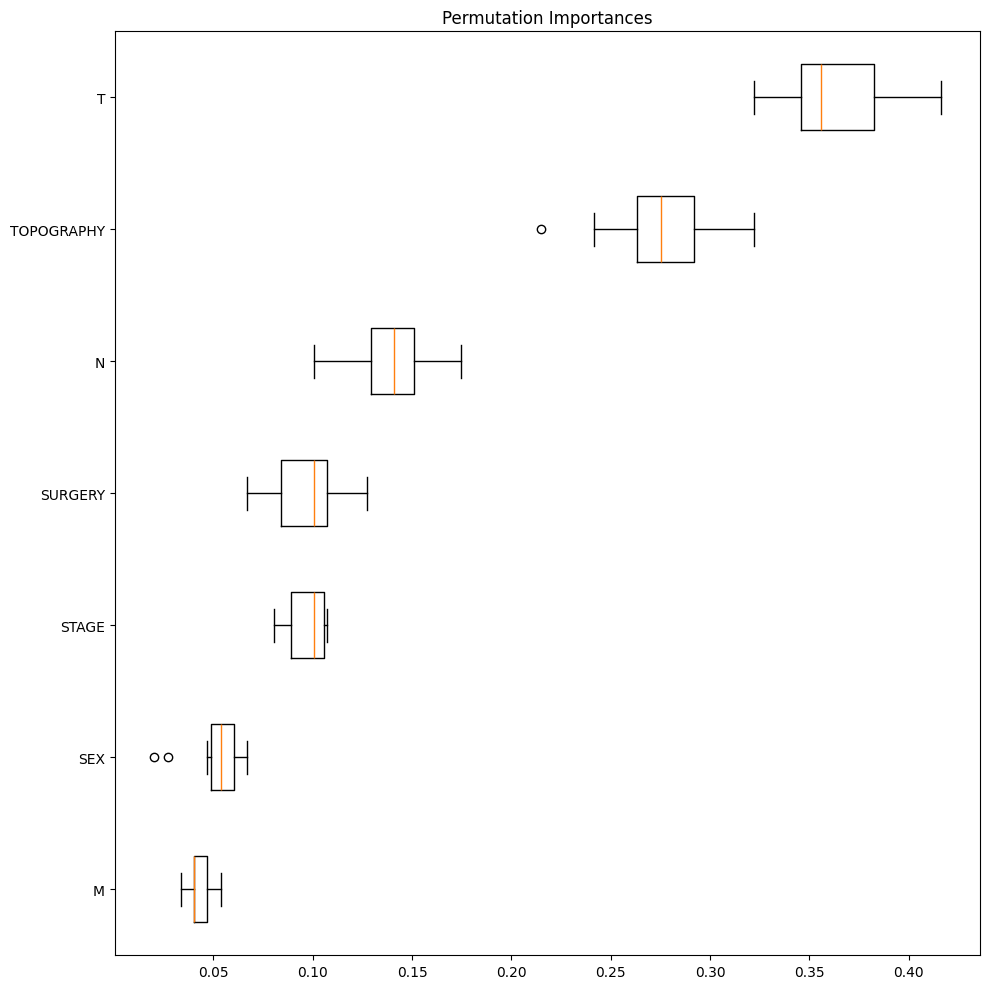

In [ ]:
def plot_perm_importance(result, sorted_idx, feature_names):

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.boxplot(
        result.importances[sorted_idx].T, vert=False, tick_labels=feature_names[sorted_idx]
    )
    ax.set_title("Permutation Importances")
    fig.tight_layout()
    plt.show()

plot_perm_importance(result, sorted_idx, feature_names)

####Permutation importance on the test set.

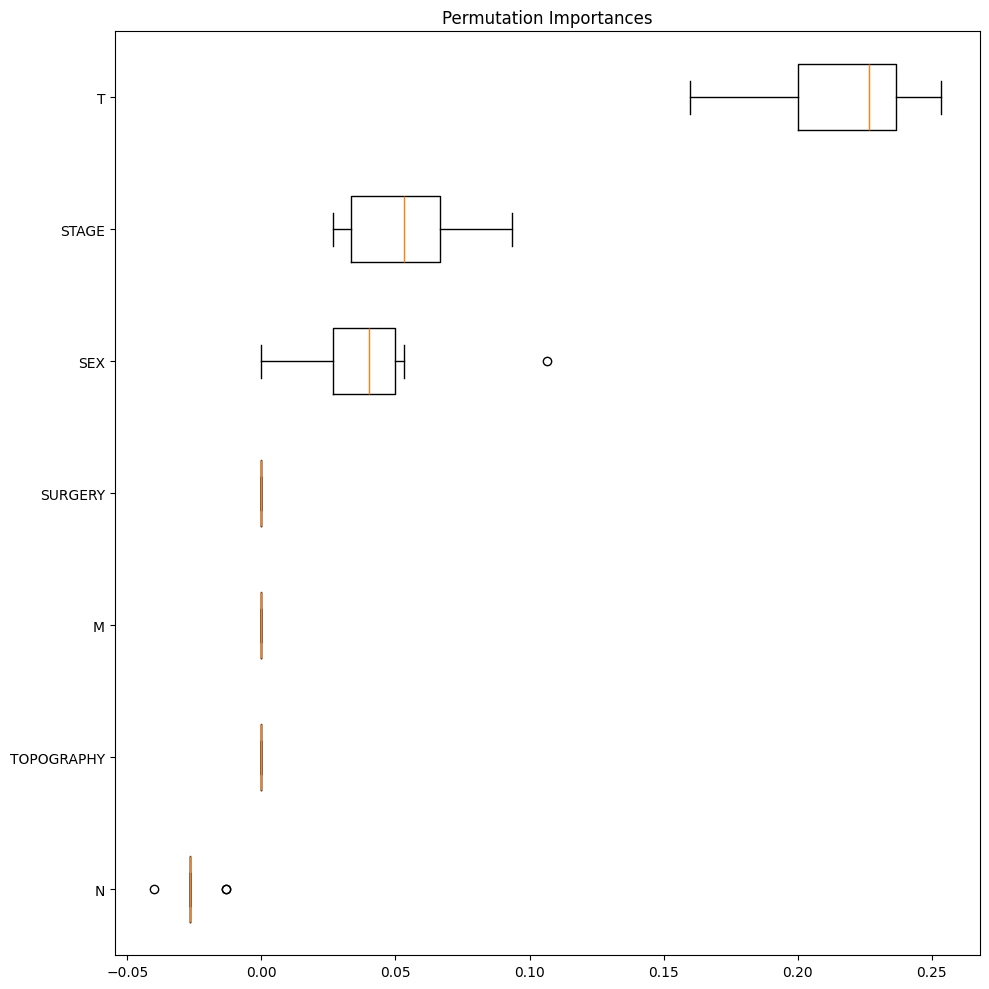

In [ ]:
result = permutation_importance(best_clf, X_test, y_test, n_repeats=10, n_jobs=2)
sorted_idx = result.importances_mean.argsort()
#result.importances[sorted_idx].T, vert=False, labels=feature_names[sorted_idx]

plot_perm_importance(result, sorted_idx, feature_names)